# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Teninlanimi/flyrank-interenship-ml/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

In [1]:
from pathlib import Path
import pandas as pd

def find_repo_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "raw" / "content_refresh_anonymized.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find the repo root containing data/raw/content_refresh_anonymized.csv")

repo_root = find_repo_root()
data_path = repo_root / "data" / "raw" / "content_refresh_anonymized.csv"

df = pd.read_csv(data_path)
print(df.shape)

(30000, 44)


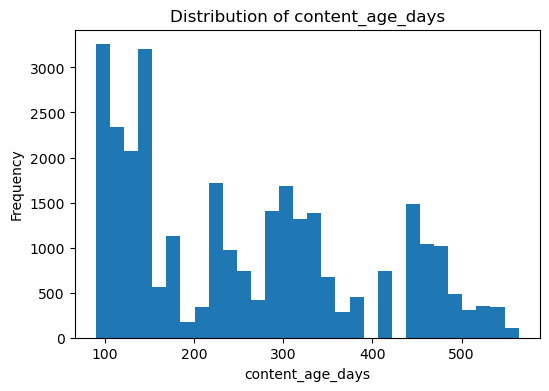

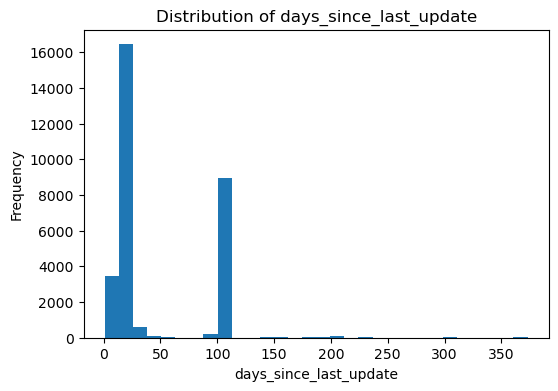

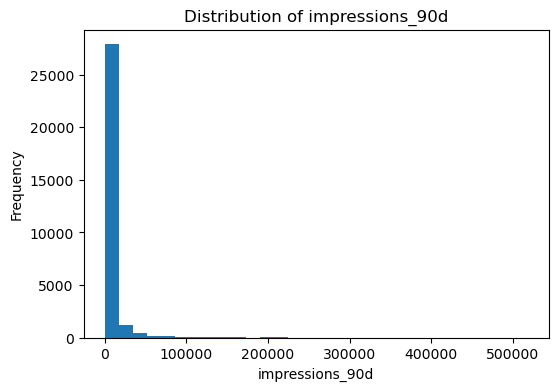

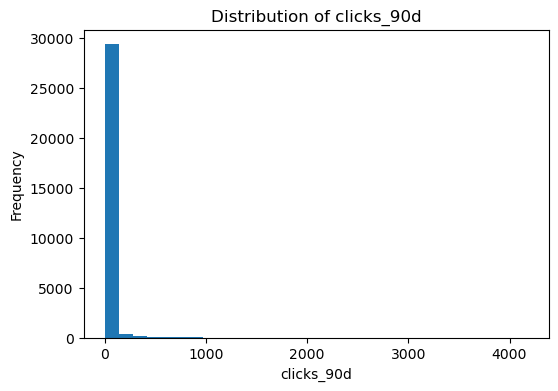

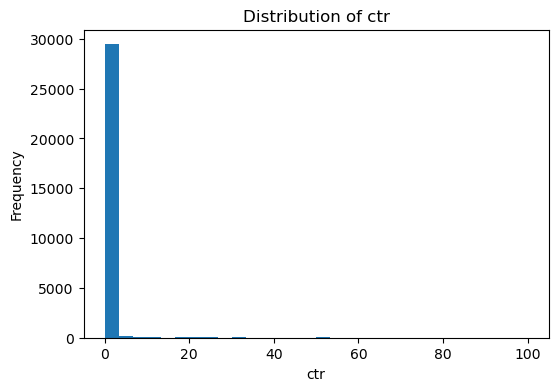

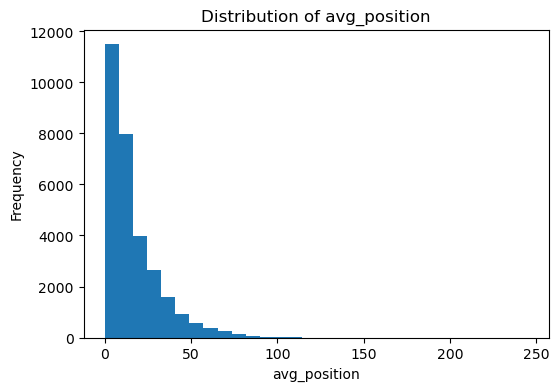

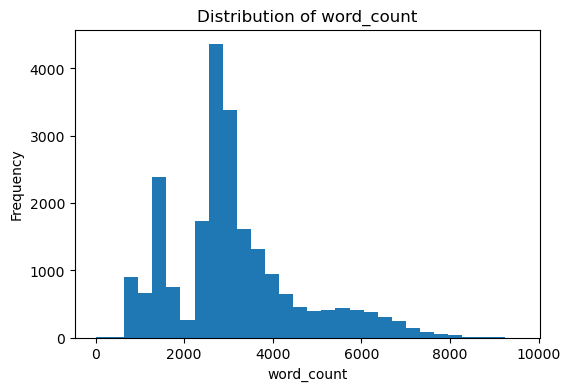

,content_age_days,days_since_last_update,impressions_90d,clicks_90d,ctr,avg_position,word_count
count,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000,30000.00000,22301.000000
mean,256.16780,46.098300,5200.366300,16.097333,0.510733,16.34238,3107.760325
std,132.70793,42.078709,16838.019547,75.076958,3.279162,15.21679,1452.382598
min,90.00000,1.000000,1.000000,0.000000,0.000000,0.00000,8.000000
25%,132.00000,20.000000,81.000000,0.000000,0.000000,6.20000,2413.000000
50%,236.00000,20.000000,731.000000,1.000000,0.070000,10.80000,2877.000000
75%,333.00000,104.000000,3615.250000,7.000000,0.290000,22.30000,3666.000000
max,564.00000,373.000000,517715.000000,4178.000000,100.000000,245.00000,9546.000000


In [2]:

import matplotlib.pyplot as plt

columns = [
    "content_age_days",
    "days_since_last_update",
    "impressions_90d",
    "clicks_90d",
    "ctr",
    "avg_position",
    "word_count"
]

for col in columns:
    plt.figure(figsize=(6,4))
    plt.hist(df[col].dropna(), bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# Summary statistics
df[columns].describe()

The numeric features show evidence of right-skewed distributions with noticeable long tails. Impressions and clicks vary widely, with median values (731 impressions and 1 click) much lower than their means (5,200 impressions and 16 clicks), indicating that a small number of pages receive exceptionally high traffic. CTR is also highly skewed, with a median of 0.07 compared with a mean of 0.51 and a maximum of 100, suggesting the presence of extreme values. Content age and days since the last update show moderate variation, while word count has a broad spread and some missing values (22,301 non-null observations out of 30,000). Overall, these distributions indicate that a few high-performing pages can strongly influence averages, so medians and distribution plots provide a more representative view of the data.

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

In [3]:
# Hypothesis: Older content is more likely to require refresh
# Compare average content age by refresh label
df["content_age_days"].corr(df["impressions_90d"])

np.float64(-0.0007426392446796379)

Signal 1: Older content tends to receive fewer impressions.

Test: Measured the correlation between content_age_days and impressions_90d.

Result: Correlation = -0.0007.

Verdict: FALSE

Reason: The correlation is essentially zero, indicating no meaningful relationship between content age and impressions in this dataset. Older pages do not consistently receive fewer impressions than newer pages.

In [4]:
df["avg_position"].corr(df["ctr"])

np.float64(-0.07259029976832462)

Signal 2: Better ranking positions are associated with higher CTR.

Test: Measured the correlation between avg_position and ctr.

Result: Correlation = -0.0726.

Verdict: MIXED

Reason: The relationship is negative, which is in the expected direction because lower position values represent better rankings. However, the correlation is weak, suggesting that ranking position alone explains only a small part of the variation in CTR.

In [5]:
df["impressions_90d"].corr(df["clicks_90d"])

np.float64(0.6962810028467803)

Signal 3: Pages with more impressions tend to receive more clicks.

Test: Measured the correlation between impressions_90d and clicks_90d.

Result: Correlation = 0.6963.

Verdict: CONFIRMED

Reason: The strong positive correlation indicates that pages with higher search visibility generally receive more clicks. This is the strong

## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

In [6]:
# Test the relationship behind the Page-One Decay Risk flag
correlation = df["avg_position"].corr(df["ctr"])

print(f"Correlation between avg_position and ctr: {correlation:.4f}")

Correlation between avg_position and ctr: -0.0726


Flag tested: Page-One Decay Risk

Rule assumption: Pages with poorer average search positions tend to have lower click-through rates (CTR).

Test: Measured the correlation between avg_position and ctr.

Result: The correlation was -0.0726.

Conclusion: The data provides partial support for the rule's assumption. The relationship is in the expected direction because lower (better) positions are associated with slightly higher CTR. However, the correlation is weak, suggesting that average position alone is not a strong predictor of CTR. This signal should therefore be combined with other metrics, such as impressions and trend direction, when prioritizing content for review.

## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

The signal audit suggests that not all commonly assumed refresh signals are equally useful. Impressions and clicks showed the strongest relationship, while content age and average position alone were weak predictors of content performance. A content team should use multiple signals together when prioritizing refresh opportunities rather than relying on a single metric or rule.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.